# Progressive Visualization Benchmark Analysis

This notebook loads benchmark reports exported by `pink-lemonade-progressive-harness` and visualizes wire transfer, latency, request counts, cache reuse, and client memory across strategies and scenarios.

### Setup & regenerating results
Select the root `.venv` kernel (or launch JupyterLab with `./dev notebook`).

From the repository root, regenerate `benchmarks/results/latest.json`:
```bash
cargo run --release -p pink-lemonade-progressive-tree --example export_reports --manifest-path rust/Cargo.toml
```

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

# Resolve results/latest.json whether Jupyter is opened from repo root or benchmarks/.
CANDIDATES = [
    Path("results/latest.json"),
    Path("benchmarks/results/latest.json"),
]
REPORT_PATH = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])
print(f"Loading {REPORT_PATH.resolve()}")

raw = json.loads(REPORT_PATH.read_text(encoding="utf-8"))
reports = raw["reports"]

workload_rows = []
step_rows = []

for rep in reports:
    scenario = rep["scenario_name"] or "custom"
    strategy = rep["strategy_name"]
    raw_bytes = max(rep["raw_points_bytes"], 1)
    budget_bytes = max(rep["memory_budget_bytes"], 1)

    for w in rep["workloads"]:
        tt = w["total_transport"]
        workload_rows.append(
            {
                "scenario": scenario,
                "strategy": strategy,
                "workload": w["name"],
                "points": rep["total_points"],
                "raw_kib": raw_bytes / 1024.0,
                "storage_kib": rep["storage_bytes"] / 1024.0,
                "storage_overhead_pct": 100.0 * (rep["storage_bytes"] - raw_bytes) / raw_bytes,
                "build_ms": rep["build_duration_ms"],
                "wire_kib": tt["total_wire_bytes"] / 1024.0,
                "completed_kib": tt["bytes_downloaded"] / 1024.0,
                "wasted_kib": tt["wasted_cancelled_bytes"] / 1024.0,
                "wire_pct_of_raw": 100.0 * tt["total_wire_bytes"] / raw_bytes,
                "requests": tt["completed_requests"],
                "cancelled": tt["cancelled_requests"],
                "mean_latency_ms": w["mean_latency_ms"],
                "peak_mem_kib": w["peak_client_memory_bytes"] / 1024.0,
                "budget_kib": budget_bytes / 1024.0,
                "network": rep["network"]["name"],
            }
        )

        cum_wire = w["open_transport"]["total_wire_bytes"]
        for idx, s in enumerate(w["steps"]):
            st = s["transport"]
            cum_wire += st["total_wire_bytes"]
            step_rows.append(
                {
                    "scenario": scenario,
                    "strategy": strategy,
                    "workload": w["name"],
                    "step_idx": idx,
                    "label": s["label"],
                    "view_min_x": s["view_min_x"],
                    "view_max_x": s["view_max_x"],
                    "view_width": s["view_width"],
                    "completed": s["completed"],
                    "latency_ms": s["latency_ms"],
                    "kernel_count": s["kernel_count"],
                    "wire_kib": st["total_wire_bytes"] / 1024.0,
                    "cum_wire_kib": cum_wire / 1024.0,
                    "wasted_kib": st["wasted_cancelled_bytes"] / 1024.0,
                    "requests": st["completed_requests"],
                    "cancelled": st["cancelled_requests"],
                    "client_mem_kib": s["client_memory_bytes"] / 1024.0,
                    "nmae_percent": s["nmae_percent"],
                }
            )

workloads_df = pd.DataFrame(workload_rows)
steps_df = pd.DataFrame(step_rows)

print(
    f"Loaded {len(reports)} reports | scenarios={list(workloads_df['scenario'].unique())} | "
    f"strategies={list(workloads_df['strategy'].unique())}"
)

Loading C:\projects\pink-lemonade\benchmarks\results\latest.json
Loaded 4 reports | scenarios=['light', 'medium'] | strategies=['naive_full_download', 'paged_moment_tree']


## 1. Summary Scorecard & Improvement vs Baseline (`naive_full_download`)

In [2]:
display(
    workloads_df[
        [
            "scenario",
            "strategy",
            "workload",
            "wire_kib",
            "wire_pct_of_raw",
            "requests",
            "cancelled",
            "mean_latency_ms",
            "peak_mem_kib",
            "budget_kib",
        ]
    ].round(2)
)

# Side-by-side wire savings & latency speedup relative to naive_full_download
if "naive_full_download" in workloads_df["strategy"].values:
    base = workloads_df[workloads_df["strategy"] == "naive_full_download"][
        ["scenario", "workload", "wire_kib", "mean_latency_ms"]
    ].rename(columns={"wire_kib": "naive_wire_kib", "mean_latency_ms": "naive_latency_ms"})
    others = workloads_df[workloads_df["strategy"] != "naive_full_download"].merge(
        base, on=["scenario", "workload"], how="left"
    )
    others["wire_reduction_x"] = others["naive_wire_kib"] / others["wire_kib"].clip(lower=1e-9)
    others["latency_speedup_x"] = others["naive_latency_ms"] / others["mean_latency_ms"].clip(lower=1e-9)
    print("\nRelative improvement vs naive_full_download (higher is better):")
    display(
        others[
            [
                "scenario",
                "strategy",
                "workload",
                "wire_reduction_x",
                "latency_speedup_x",
                "storage_overhead_pct",
            ]
        ].round(2)
    )

,scenario,strategy,workload,wire_kib,wire_pct_of_raw,requests,cancelled,mean_latency_ms,peak_mem_kib,budget_kib
0,light,naive_full_download,cold_overview,234.38,100.00,2,0,69.00,234.38,1024.0
1,light,naive_full_download,progressive_zoom_in,234.38,100.00,2,0,11.50,234.38,1024.0
2,light,naive_full_download,lateral_pan,234.38,100.00,2,0,8.62,234.38,1024.0
3,light,naive_full_download,jump_and_revisit,234.38,100.00,2,0,11.50,234.38,1024.0
4,light,naive_full_download,rapid_interrupt_pan,234.38,100.00,2,5,69.00,234.38,1024.0
5,light,paged_moment_tree,cold_overview,254.67,108.66,8,0,72.00,263.56,1024.0
6,light,paged_moment_tree,progressive_zoom_in,254.67,108.66,8,0,12.00,263.56,1024.0
7,light,paged_moment_tree,lateral_pan,50.67,21.62,21,0,69.88,52.34,1024.0
8,light,paged_moment_tree,jump_and_revisit,68.80,29.35,18,0,62.67,70.96,1024.0
9,light,paged_moment_tree,rapid_interrupt_pan,18.17,7.75,6,5,94.00,18.75,1024.0



Relative improvement vs naive_full_download (higher is better):


,scenario,strategy,workload,wire_reduction_x,latency_speedup_x,storage_overhead_pct
0,light,paged_moment_tree,cold_overview,0.92,0.96,8.66
1,light,paged_moment_tree,progressive_zoom_in,0.92,0.96,8.66
2,light,paged_moment_tree,lateral_pan,4.63,0.12,8.66
3,light,paged_moment_tree,jump_and_revisit,3.41,0.18,8.66
4,light,paged_moment_tree,rapid_interrupt_pan,12.90,0.73,8.66
5,medium,paged_moment_tree,cold_overview,11.63,13.73,8.60
6,medium,paged_moment_tree,progressive_zoom_in,65.31,45.63,8.60
7,medium,paged_moment_tree,lateral_pan,485.68,35.19,8.60
8,medium,paged_moment_tree,jump_and_revisit,312.46,43.01,8.60
9,medium,paged_moment_tree,rapid_interrupt_pan,207.31,28.67,8.60


## 2. Workload Comparison for a Scenario
Change `SCENARIO` below (`"light"`, `"medium"`, `"constrained_mobile"`, etc.) to inspect any scenario.

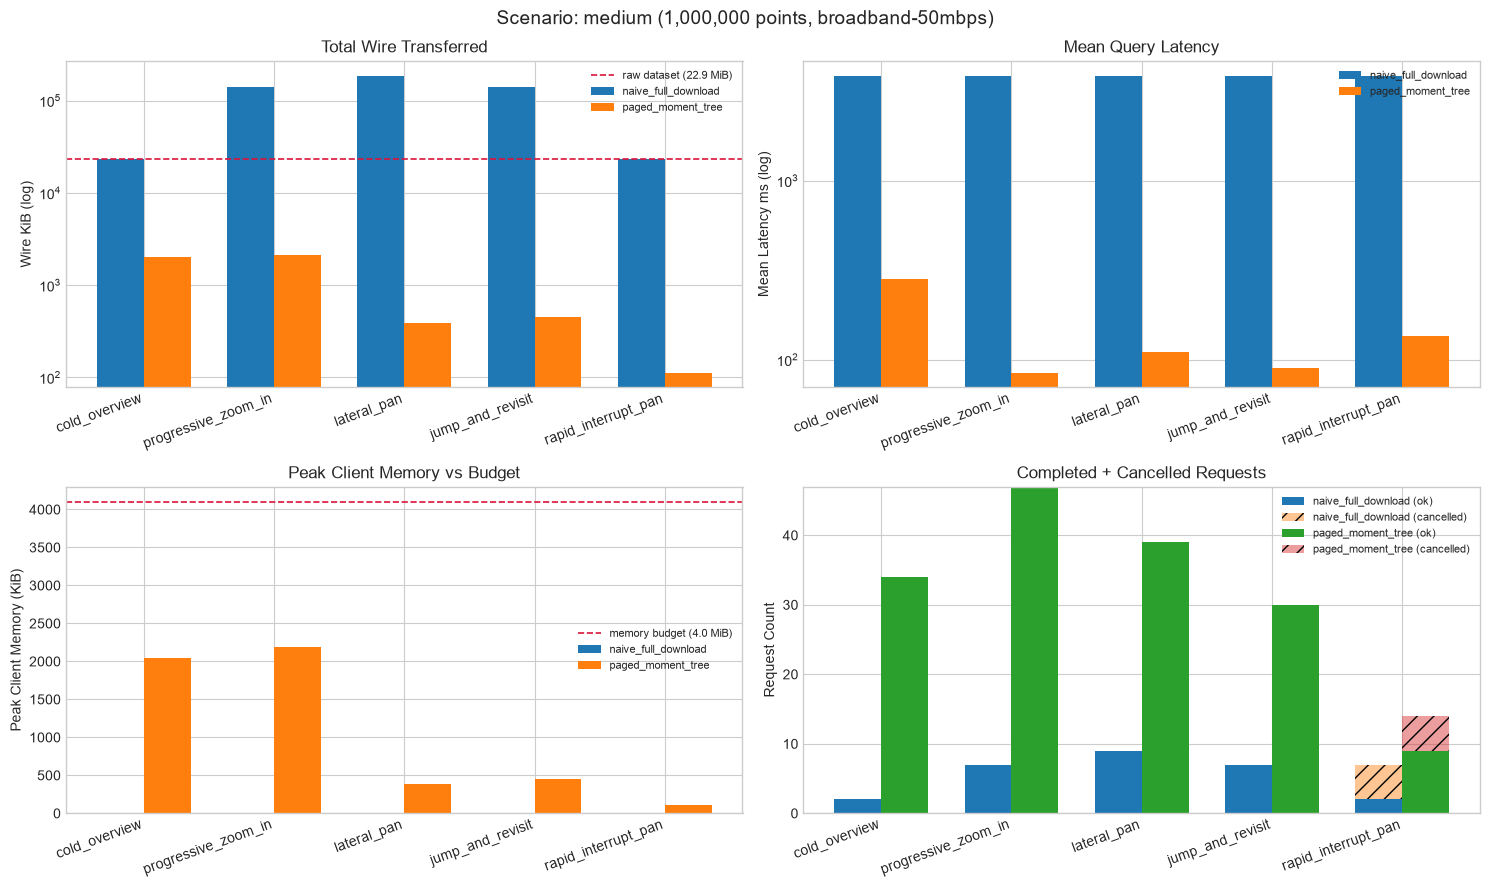

In [3]:
SCENARIO = "medium" if "medium" in workloads_df["scenario"].values else workloads_df["scenario"].iloc[0]
sub = workloads_df[workloads_df["scenario"] == SCENARIO]
workloads = list(sub["workload"].unique())
strategies = list(sub["strategy"].unique())
x = np.arange(len(workloads))
bar_w = 0.72 / max(len(strategies), 1)

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
fig.suptitle(f"Scenario: {SCENARIO} ({int(sub['points'].iloc[0]):,} points, {sub['network'].iloc[0]})", fontsize=14)

raw_kib = sub["raw_kib"].iloc[0]
budget_kib = sub["budget_kib"].iloc[0]

for i, strat in enumerate(strategies):
    s = sub[sub["strategy"] == strat].set_index("workload").reindex(workloads)
    offset = (i - (len(strategies) - 1) / 2.0) * bar_w

    axes[0, 0].bar(x + offset, s["wire_kib"], width=bar_w, label=strat)
    axes[0, 1].bar(x + offset, s["mean_latency_ms"], width=bar_w, label=strat)
    axes[1, 0].bar(x + offset, s["peak_mem_kib"], width=bar_w, label=strat)
    axes[1, 1].bar(x + offset, s["requests"], width=bar_w, label=f"{strat} (ok)")
    axes[1, 1].bar(
        x + offset,
        s["cancelled"],
        bottom=s["requests"],
        width=bar_w,
        alpha=0.45,
        hatch="//",
        label=f"{strat} (cancelled)",
    )

axes[0, 0].axhline(raw_kib, color="crimson", linestyle="--", linewidth=1.2, label=f"raw dataset ({raw_kib/1024:.1f} MiB)")
axes[0, 0].set_yscale("log")
axes[0, 0].set_ylabel("Wire KiB (log)")
axes[0, 0].set_title("Total Wire Transferred")

axes[0, 1].set_yscale("log")
axes[0, 1].set_ylabel("Mean Latency ms (log)")
axes[0, 1].set_title("Mean Query Latency")

axes[1, 0].axhline(budget_kib, color="crimson", linestyle="--", linewidth=1.2, label=f"memory budget ({budget_kib/1024:.1f} MiB)")
axes[1, 0].set_ylabel("Peak Client Memory (KiB)")
axes[1, 0].set_title("Peak Client Memory vs Budget")

axes[1, 1].set_ylabel("Request Count")
axes[1, 1].set_title("Completed + Cancelled Requests")

for ax in axes.flat:
    ax.set_xticks(x)
    ax.set_xticklabels(workloads, rotation=20, ha="right")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## 3. Step-by-Step Drill-Down (Where Do Bytes & Latency Actually Go?)
Inspects each interaction step inside `SCENARIO` to highlight overview cost, cache reuse during lateral panning, cache hits on revisit, and kernel counts.

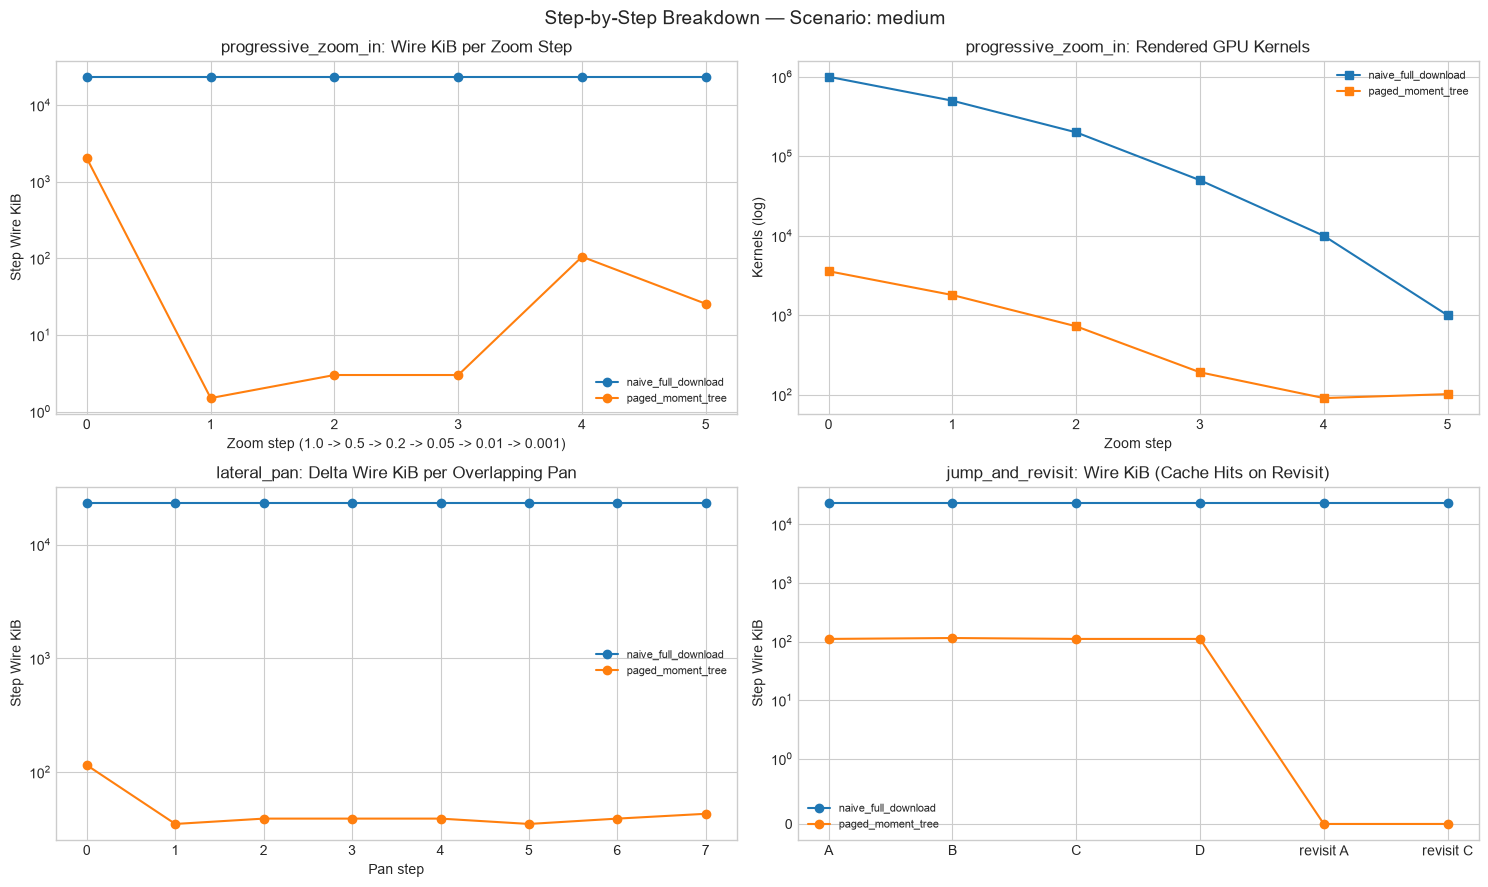

In [4]:
sc_steps = steps_df[steps_df["scenario"] == SCENARIO]
strategies = list(sc_steps["strategy"].unique())

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
fig.suptitle(f"Step-by-Step Breakdown — Scenario: {SCENARIO}", fontsize=14)

# 1. progressive_zoom_in: per-step wire KiB
ax = axes[0, 0]
zoom = sc_steps[sc_steps["workload"] == "progressive_zoom_in"]
for strat in strategies:
    s = zoom[zoom["strategy"] == strat]
    ax.plot(s["step_idx"], s["wire_kib"], marker="o", label=strat)
ax.set_yscale("symlog", linthresh=1.0)
ax.set_title("progressive_zoom_in: Wire KiB per Zoom Step")
ax.set_xlabel("Zoom step (1.0 -> 0.5 -> 0.2 -> 0.05 -> 0.01 -> 0.001)")
ax.set_ylabel("Step Wire KiB")
ax.legend(fontsize=8)

# 2. progressive_zoom_in: rendered kernel count per step
ax = axes[0, 1]
for strat in strategies:
    s = zoom[zoom["strategy"] == strat]
    ax.plot(s["step_idx"], s["kernel_count"], marker="s", label=strat)
ax.set_yscale("log")
ax.set_title("progressive_zoom_in: Rendered GPU Kernels")
ax.set_xlabel("Zoom step")
ax.set_ylabel("Kernels (log)")
ax.legend(fontsize=8)

# 3. lateral_pan: per-step wire KiB (shows cache reuse on overlapping pan)
ax = axes[1, 0]
pan = sc_steps[sc_steps["workload"] == "lateral_pan"]
for strat in strategies:
    s = pan[pan["strategy"] == strat]
    ax.plot(s["step_idx"], s["wire_kib"], marker="o", label=strat)
ax.set_yscale("symlog", linthresh=1.0)
ax.set_title("lateral_pan: Delta Wire KiB per Overlapping Pan")
ax.set_xlabel("Pan step")
ax.set_ylabel("Step Wire KiB")
ax.legend(fontsize=8)

# 4. jump_and_revisit: per-step wire KiB (revisit steps 4 & 5 show cache hits)
ax = axes[1, 1]
jump = sc_steps[sc_steps["workload"] == "jump_and_revisit"]
for strat in strategies:
    s = jump[jump["strategy"] == strat]
    ax.plot(s["step_idx"], s["wire_kib"], marker="o", label=strat)
ax.set_yscale("symlog", linthresh=1.0)
ax.set_xticks(range(6))
ax.set_xticklabels(["A", "B", "C", "D", "revisit A", "revisit C"])
ax.set_title("jump_and_revisit: Wire KiB (Cache Hits on Revisit)")
ax.set_ylabel("Step Wire KiB")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## 4. Cross-Scenario Scaling (`light` vs `medium` vs `constrained_mobile`)
Shows total wire bytes as a **percentage of the raw dataset** and mean latency across scenarios.

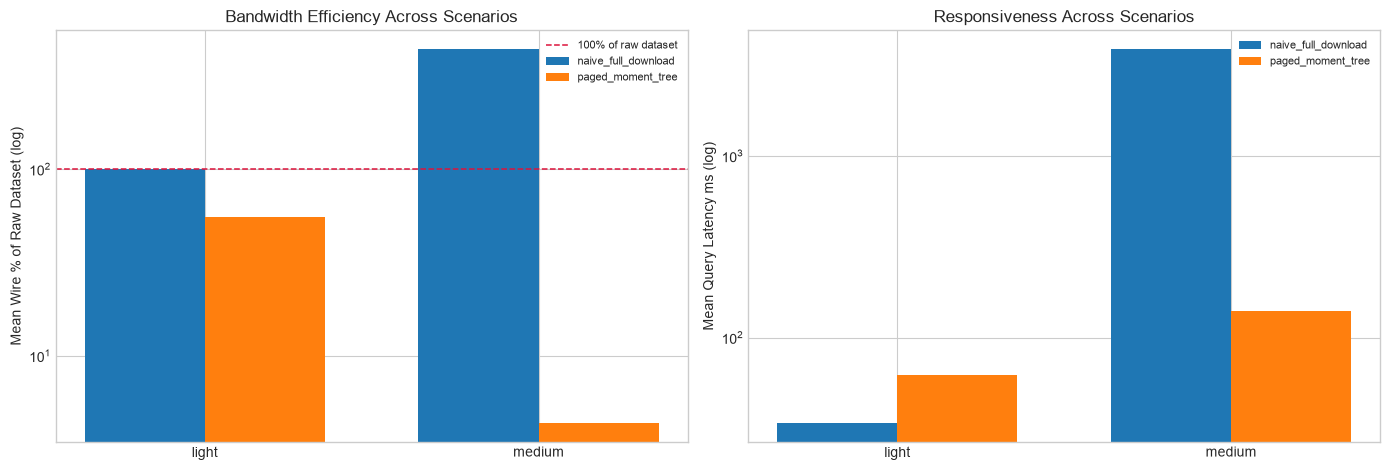

In [5]:
scenarios = list(workloads_df["scenario"].unique())
strategies = list(workloads_df["strategy"].unique())

agg = (
    workloads_df.groupby(["scenario", "strategy"], as_index=False)
    .agg(
        mean_wire_pct=("wire_pct_of_raw", "mean"),
        mean_latency_ms=("mean_latency_ms", "mean"),
        total_wire_mib=("wire_kib", lambda s: s.sum() / 1024.0),
    )
)

x = np.arange(len(scenarios))
bar_w = 0.72 / max(len(strategies), 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for i, strat in enumerate(strategies):
    s = agg[agg["strategy"] == strat].set_index("scenario").reindex(scenarios)
    offset = (i - (len(strategies) - 1) / 2.0) * bar_w
    axes[0].bar(x + offset, s["mean_wire_pct"], width=bar_w, label=strat)
    axes[1].bar(x + offset, s["mean_latency_ms"], width=bar_w, label=strat)

axes[0].axhline(100.0, color="crimson", linestyle="--", linewidth=1.1, label="100% of raw dataset")
axes[0].set_yscale("log")
axes[0].set_ylabel("Mean Wire % of Raw Dataset (log)")
axes[0].set_title("Bandwidth Efficiency Across Scenarios")

axes[1].set_yscale("log")
axes[1].set_ylabel("Mean Query Latency ms (log)")
axes[1].set_title("Responsiveness Across Scenarios")

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(scenarios)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()